<a href="https://colab.research.google.com/github/Faizan-Mohammed-Yahya/DATA-QUALITY-ML-STUDY-REPO/blob/main/phase_2_data_quality_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 2: Data Quality and Chronic Kidney Disease Prediction

This phase repeats the same method in a healthcare domain. The model predicts whether a record is labelled as chronic kidney disease (CKD).


## 1. Import libraries

The project uses Pandas for data work, Matplotlib for charts, and scikit-learn for modelling.


In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, balanced_accuracy_score, confusion_matrix
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

RANDOM_SEEDS = [42, 43, 44]
pd.set_option("display.max_columns", 30)

## 2. Load the dataset

The original `ckd.csv` file is read without editing it.

In [2]:
DATA_FILE = Path("ckd.csv")

if not DATA_FILE.exists():
    from google.colab import files
    files.upload()

raw_data = pd.read_csv(DATA_FILE, dtype=str, keep_default_na=False)

target_column = "class"
positive_label = "ckd"
numeric_columns = [
    "age", "bp", "bgr", "bu", "sc", "sod", "pot",
    "hemo", "pcv", "wbcc", "rbcc"
]

allowed_categories = {
    "sg": ["1.005", "1.01", "1.015", "1.02", "1.025"],
    "al": list("012345"), "su": list("012345"),
    "rbc": ["normal", "abnormal"], "pc": ["normal", "abnormal"],
    "pcc": ["present", "notpresent"], "ba": ["present", "notpresent"],
    "appet": ["good", "poor"]
}
for field in ["htn", "dm", "cad", "pe", "ane"]:
    allowed_categories[field] = ["yes", "no"]

# These are broad plausibility limits, not medical reference intervals.
valid_ranges = {column: (0, None) for column in numeric_columns}
valid_ranges["age"] = (0, 120)
valid_ranges["pcv"] = (0, 100)

In [3]:
raw_data.shape


(400, 25)

## 3. Prepare feature types

Question marks, blank strings, and `NaN` text are treated as missing. Numeric fields are then converted to numbers.


In [4]:
features = raw_data.drop(columns=target_column).copy()

for column in features.columns:
    missing_markers = features[column].str.strip().isin(["?", "NaN", ""])
    features.loc[missing_markers, column] = np.nan

for column in numeric_columns:
    features[column] = pd.to_numeric(features[column], errors="coerce")

categorical_columns = [
    column for column in features.columns if column not in numeric_columns
]

clean_labels = raw_data[target_column].str.strip()
target = (clean_labels == positive_label).astype(int)

features.dtypes.to_frame("data_type")


,data_type
age,float64
bp,float64
sg,object
al,object
su,object
rbc,object
pc,object
pcc,object
ba,object
bgr,float64


## 4. Missing values

Missing values are counted before any treatment is applied.


In [5]:
missing_profile = pd.DataFrame({
    "missing_count": features.isna().sum(),
    "missing_percent": features.isna().mean().mul(100)
}).sort_values("missing_count", ascending=False)

missing_profile[missing_profile["missing_count"] > 0]

,missing_count,missing_percent
rbc,152,38.00
rbcc,131,32.75
wbcc,106,26.50
pot,88,22.00
sod,87,21.75
pcv,71,17.75
pc,65,16.25
hemo,52,13.00
su,49,12.25
sg,47,11.75


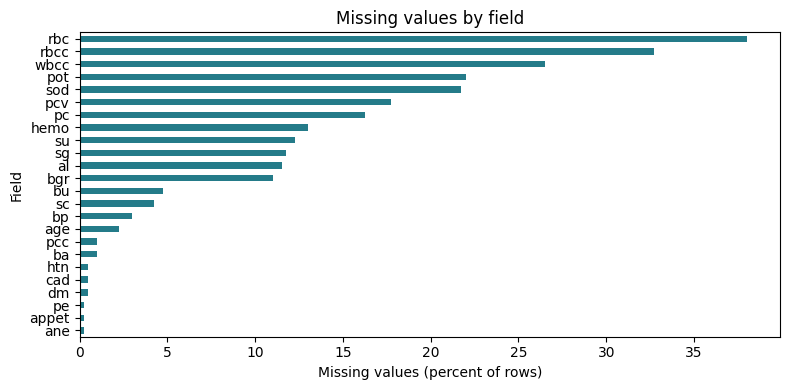

In [6]:
missing_profile[missing_profile["missing_count"] > 0].sort_values(
    "missing_percent"
).plot.barh(y="missing_percent", figsize=(8, 4), color="#247b89", legend=False)
plt.title("Missing values by field")
plt.xlabel("Missing values (percent of rows)")
plt.ylabel("Field")
plt.tight_layout()
plt.savefig("phase2_missing_values.png", dpi=180)
plt.show()


**Finding:** The dataset contains 1,012 missing feature cells. This is 10.54% of all feature cells, much higher than in Phase 1.


## 5. Duplicate records

Exact duplicates are checked using all features and the target together.

In [7]:
model_data = features.assign(target=target)
duplicate_count = int(model_data.duplicated().sum())

pd.DataFrame({
    "duplicate_rows": [duplicate_count],
    "percentage_of_dataset": [duplicate_count / len(model_data) * 100]
})


,duplicate_rows,percentage_of_dataset
0,0,0.0


**Finding:** No exact duplicate rows were found, so E2 should reproduce the baseline result.

## 6. Outliers

The IQR rule flags unusually low or high numeric values. A flag is not automatically proof that a value is wrong.


In [8]:
def calculate_iqr_bounds(data, columns):
    bounds = {}
    for column in columns:
        q1, q3 = data[column].quantile([0.25, 0.75])
        iqr = q3 - q1
        if pd.notna(iqr) and iqr > 0:
            bounds[column] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)
    return bounds


full_iqr_bounds = calculate_iqr_bounds(features, numeric_columns)
outlier_counts = {}
for column, (lower, upper) in full_iqr_bounds.items():
    outlier_counts[column] = int(
        ((features[column] < lower) | (features[column] > upper)).sum()
    )

pd.Series(outlier_counts, name="IQR_flag_count").sort_values(ascending=False).to_frame()


,IQR_flag_count
sc,51
bu,38
bp,36
bgr,34
sod,16
age,10
wbcc,10
pot,4
hemo,1
pcv,1


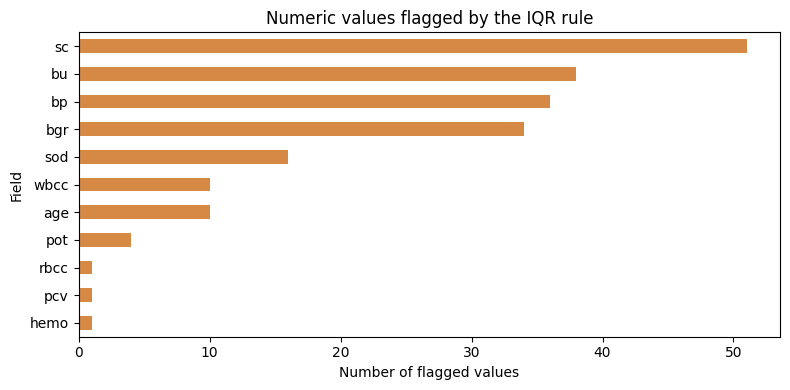

In [9]:
pd.Series(outlier_counts).sort_values().plot.barh(figsize=(8, 4), color="#d58945")
plt.title("Numeric values flagged by the IQR rule")
plt.xlabel("Number of flagged values")
plt.ylabel("Field")
plt.tight_layout()
plt.savefig("phase2_outlier_flags.png", dpi=180)
plt.show()


**Finding:** Some numeric tails are flagged, but plausible extreme values are kept in the baseline. E3 tests clipping separately.


## 7. Invalid or inconsistent values

Categories are compared with documented values. Numeric fields are checked against broad plausibility limits.

In [10]:
def standardise_values(data):
    cleaned = data.copy()
    for column, accepted_values in allowed_categories.items():
        cleaned[column] = cleaned[column].str.strip()
        cleaned[column] = cleaned[column].where(
            cleaned[column].isin(accepted_values), np.nan
        )

    for column, (lower, upper) in valid_ranges.items():
        invalid = cleaned[column] < lower
        if upper is not None:
            invalid = invalid | (cleaned[column] > upper)
        cleaned.loc[invalid, column] = np.nan
    return cleaned


standardised_features = standardise_values(features)
changed_by_rules = features.notna() & (
    features.ne(standardised_features) | standardised_features.isna()
)

changed_by_rules.sum().sort_values(ascending=False).to_frame("values_changed")


,values_changed
dm,1
age,0
sg,0
bp,0
su,0
rbc,0
pc,0
al,0
pcc,0
ba,0


**Finding:** One category contains extra whitespace. Standardisation changes that training value but does not improve the main test result.

## 8. Class distribution

Both the count and percentage of each target class are examined.


In [11]:
class_profile = pd.DataFrame({
    "count": target.value_counts().sort_index(),
    "percent": target.value_counts(normalize=True).sort_index().mul(100)
})
class_profile.index = ["Negative class", "Positive class"]
class_profile

,count,percent
Negative class,150,37.5
Positive class,250,62.5


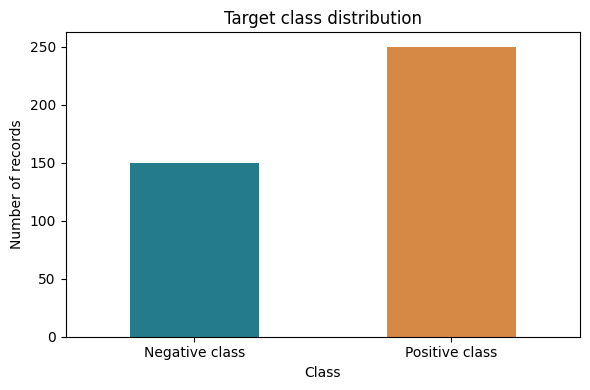

In [12]:
class_profile["count"].plot.bar(figsize=(6, 4), color=["#247b89", "#d58945"])
plt.title("Target class distribution")
plt.xlabel("Class")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("phase2_class_distribution.png", dpi=180)
plt.show()


**Finding:** CKD is the positive class and represents 62.5% of the data. The negative class is smaller, which is different from Phase 1.

## 9. Create a fair train/test split

Rows with the same canonical feature values are placed in only one split. This prevents duplicate information from leaking into the test set.


In [13]:
def make_grouped_split(data, labels, seed):
    canonical = standardise_values(data).fillna("__MISSING__").astype(str)
    group_ids = pd.util.hash_pandas_object(canonical, index=False).astype(str)

    group_labels = pd.DataFrame({"group": group_ids, "target": labels})
    group_labels = group_labels.groupby("group", sort=False)["target"].agg(
        lambda values: int(values.mean() >= 0.5)
    )

    train_groups, test_groups = train_test_split(
        group_labels.index,
        test_size=0.20,
        stratify=group_labels.values,
        random_state=seed
    )

    train_index = data.index[group_ids.isin(train_groups)]
    test_index = data.index[group_ids.isin(test_groups)]
    return train_index, test_index


train_index, test_index = make_grouped_split(features, target, seed=42)
print("Training rows:", len(train_index))
print("Testing rows:", len(test_index))

Training rows: 320
Testing rows: 80


## 10. Modelling method

Every experiment uses the same logistic regression approach. Only the named data-quality intervention changes.


In [14]:
experiment_names = {
    "E0": "Baseline placeholders",
    "E1": "Median and mode imputation",
    "E2": "Remove exact training duplicates",
    "E3": "Clip training IQR tails",
    "E4": "Standardise categories and invalid values",
    "E5": "Balanced class weights",
    "E6": "Combined E1, E2, E4 and E5"
}


def prepare_experiment(data, labels, train_rows, test_rows, experiment):
    x_train = data.loc[train_rows].copy()
    x_test = data.loc[test_rows].copy()
    y_train = labels.loc[train_rows].copy()
    y_test = labels.loc[test_rows].copy()
    removed_rows = 0
    changed_train = 0
    changed_test = 0

    if experiment in ["E2", "E6"]:
        keep = ~x_train.assign(target=y_train).duplicated()
        removed_rows = int((~keep).sum())
        x_train, y_train = x_train.loc[keep], y_train.loc[keep]

    if experiment in ["E4", "E6"]:
        clean_train = standardise_values(x_train)
        clean_test = standardise_values(x_test)
        changed_train = int((x_train.notna() & (x_train.ne(clean_train) | clean_train.isna())).sum().sum())
        changed_test = int((x_test.notna() & (x_test.ne(clean_test) | clean_test.isna())).sum().sum())
        x_train, x_test = clean_train, clean_test

    if experiment == "E3":
        training_bounds = calculate_iqr_bounds(x_train, numeric_columns)
        for column, (lower, upper) in training_bounds.items():
            changed_train += int(((x_train[column] < lower) | (x_train[column] > upper)).sum())
            changed_test += int(((x_test[column] < lower) | (x_test[column] > upper)).sum())
            x_train[column] = x_train[column].clip(lower, upper)
            x_test[column] = x_test[column].clip(lower, upper)

    return x_train, x_test, y_train, y_test, removed_rows, changed_train, changed_test

In [15]:
def build_model(experiment, seed):
    use_statistical_imputation = experiment in ["E1", "E6"]

    numeric_imputer = SimpleImputer(
        strategy="median" if use_statistical_imputation else "constant",
        fill_value=0,
        keep_empty_features=True
    )
    category_imputer = SimpleImputer(
        strategy="most_frequent" if use_statistical_imputation else "constant",
        fill_value="__MISSING__",
        keep_empty_features=True
    )

    preprocessing = ColumnTransformer([
        ("numeric", make_pipeline(numeric_imputer, StandardScaler()), numeric_columns),
        ("category", make_pipeline(category_imputer, OneHotEncoder(handle_unknown="ignore")), categorical_columns)
    ])

    classifier = LogisticRegression(
        C=1.0,
        solver="liblinear",
        max_iter=2000,
        tol=1e-6,
        class_weight="balanced" if experiment in ["E5", "E6"] else None,
        random_state=seed
    )
    return make_pipeline(preprocessing, classifier)

In [16]:
def evaluate_experiment(experiment, seed=42):
    train_rows, test_rows = make_grouped_split(features, target, seed)
    prepared = prepare_experiment(
        features, target, train_rows, test_rows, experiment
    )
    x_train, x_test, y_train, y_test, removed, changed_train, changed_test = prepared
    model = build_model(experiment, seed)

    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        with threadpool_limits(limits=1):
            model.fit(x_train, y_train)
            probability = model.predict_proba(x_test)[:, 1]

    prediction = (probability >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, prediction, labels=[0, 1]).ravel()

    return {
        "experiment": experiment,
        "intervention": experiment_names[experiment],
        "seed": seed,
        "train_rows": len(x_train), "test_rows": len(x_test),
        "removed_train_rows": removed,
        "rule_changed_train_cells": changed_train,
        "rule_changed_test_cells": changed_test,
        "accuracy": accuracy_score(y_test, prediction),
        "precision": precision_score(y_test, prediction, zero_division=0),
        "recall": recall_score(y_test, prediction, zero_division=0),
        "f1": f1_score(y_test, prediction, zero_division=0),
        "macro_f1": f1_score(y_test, prediction, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_test, prediction),
        "roc_auc": roc_auc_score(y_test, probability),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)
    }


def show_result(result):
    columns = ["experiment", "accuracy", "precision", "recall", "f1", "roc_auc"]
    return pd.DataFrame([result])[columns].round(6)


## 11. E0 — Original baseline

Missing values use simple placeholders. No quality intervention is applied.

In [17]:
main_results = []
e0_result = evaluate_experiment("E0")
main_results.append(e0_result)
show_result(e0_result)

,experiment,accuracy,precision,recall,f1,roc_auc
0,E0,0.9875,1.0,0.98,0.989899,0.98


## 12. E1 — Missing-value treatment

Numeric gaps use the training median. Categorical gaps use the training mode.


In [18]:
e1_result = evaluate_experiment("E1")
main_results.append(e1_result)
show_result(e1_result)

,experiment,accuracy,precision,recall,f1,roc_auc
0,E1,0.975,1.0,0.96,0.979592,0.998667


## 13. E2 — Duplicate treatment

Exact duplicates are removed from the training set only. The test set stays fixed.


In [19]:
e2_result = evaluate_experiment("E2")
main_results.append(e2_result)
show_result(e2_result)


,experiment,accuracy,precision,recall,f1,roc_auc
0,E2,0.9875,1.0,0.98,0.989899,0.98


## 14. E3 — Outlier treatment

IQR limits learned from the training data are used to clip numeric values in both splits.

In [20]:
e3_result = evaluate_experiment("E3")
main_results.append(e3_result)
show_result(e3_result)


,experiment,accuracy,precision,recall,f1,roc_auc
0,E3,1.0,1.0,1.0,1.0,1.0


## 15. E4 — Invalid and inconsistent values

Categories are standardised and values outside the documented rules become missing.


In [21]:
e4_result = evaluate_experiment("E4")
main_results.append(e4_result)
show_result(e4_result)

,experiment,accuracy,precision,recall,f1,roc_auc
0,E4,0.9875,1.0,0.98,0.989899,0.98


## 16. E5 — Class-imbalance treatment

Balanced class weights give more importance to the smaller class during training.

In [22]:
e5_result = evaluate_experiment("E5")
main_results.append(e5_result)
show_result(e5_result)

,experiment,accuracy,precision,recall,f1,roc_auc
0,E5,0.9875,1.0,0.98,0.989899,0.98


## 17. E6 — Combined selected pipeline

The final pipeline combines imputation, duplicate removal, category/range rules, and balanced class weights.


In [23]:
e6_result = evaluate_experiment("E6")
main_results.append(e6_result)
show_result(e6_result)

,experiment,accuracy,precision,recall,f1,roc_auc
0,E6,0.9625,1.0,0.94,0.969072,0.998667


## 18. Compare the experiments

Seed 42 is the main split used in the report.


In [24]:
results = pd.DataFrame(main_results)
baseline_f1 = results.loc[results["experiment"] == "E0", "f1"].iloc[0]
results["delta_f1"] = results["f1"] - baseline_f1

result_columns = [
    "experiment", "accuracy", "precision", "recall",
    "f1", "roc_auc", "delta_f1"
]
results[result_columns].round(6)

,experiment,accuracy,precision,recall,f1,roc_auc,delta_f1
0,E0,0.9875,1.0,0.98,0.989899,0.980000,0.000000
1,E1,0.9750,1.0,0.96,0.979592,0.998667,-0.010307
2,E2,0.9875,1.0,0.98,0.989899,0.980000,0.000000
3,E3,1.0000,1.0,1.00,1.000000,1.000000,0.010101
4,E4,0.9875,1.0,0.98,0.989899,0.980000,0.000000
5,E5,0.9875,1.0,0.98,0.989899,0.980000,0.000000
6,E6,0.9625,1.0,0.94,0.969072,0.998667,-0.020827


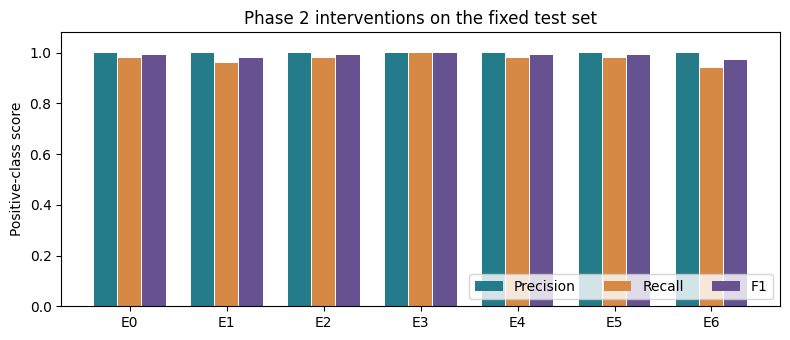

In [25]:
x_positions = np.arange(len(results))
fig, ax = plt.subplots(figsize=(8, 3.5))

for shift, metric, label, colour in [
    (-0.25, "precision", "Precision", "#247b89"),
    (0, "recall", "Recall", "#d58945"),
    (0.25, "f1", "F1", "#665191")
]:
    ax.bar(x_positions + shift, results[metric], width=0.24, label=label, color=colour)

ax.set_xticks(x_positions, results["experiment"])
ax.set_ylim(0, 1.08)
ax.set_ylabel("Positive-class score")
ax.set_title("Phase 2 interventions on the fixed test set")
ax.legend(ncol=3, loc="lower right")
fig.tight_layout()
fig.savefig("04_phase2_performance.png", dpi=180)
plt.show()

**Main result:** Outlier clipping (E3) changed the main-split F1 from 0.9899 to 1.0000. This gain did not repeat across all tested splits, so it should not be treated as a general improvement.

## 19. Check sensitivity to the train/test split

Seeds 43 and 44 test whether the pattern is stable on two additional grouped splits.


In [26]:
all_results = main_results.copy()
for seed in [43, 44]:
    for experiment in experiment_names:
        all_results.append(evaluate_experiment(experiment, seed=seed))

all_seed_results = pd.DataFrame(all_results)
for metric in ["f1", "macro_f1", "accuracy", "recall", "roc_auc"]:
    baseline_by_seed = all_seed_results[
        all_seed_results["experiment"] == "E0"
    ].set_index("seed")[metric]
    all_seed_results["delta_" + metric] = (
        all_seed_results[metric] - all_seed_results["seed"].map(baseline_by_seed)
    )

all_seed_results.groupby("experiment")[["f1", "recall", "roc_auc"]].agg(["mean", "std"]).round(4)

f1          recall         roc_auc        
              mean     std    mean     std    mean     std
experiment                                                
E0          0.9966  0.0058  0.9933  0.0115  0.9933  0.0115
E1          0.9932  0.0118  0.9867  0.0231  0.9996  0.0008
E2          0.9966  0.0058  0.9933  0.0115  0.9933  0.0115
E3          1.0000  0.0000  1.0000  0.0000  1.0000  0.0000
E4          0.9966  0.0058  0.9933  0.0115  0.9933  0.0115
E5          0.9966  0.0058  0.9933  0.0115  0.9933  0.0115
E6          0.9897  0.0179  0.9800  0.0346  0.9996  0.0008

## 20. Save reproducible outputs

The result tables and profile files are generated directly from the calculations above.


In [27]:
field_profile = pd.DataFrame({
    "field": features.columns,
    "missing_count": features.isna().sum().values,
    "missing_percent": features.isna().mean().mul(100).values,
    "unique_nonmissing": features.nunique().values
})

profile_summary = {
    "rows": int(len(features)),
    "features": int(features.shape[1]),
    "missing_cells": int(features.isna().sum().sum()),
    "rows_with_missing": int(features.isna().any(axis=1).sum()),
    "exact_duplicate_extras": duplicate_count,
    "positive_count": int(target.sum()),
    "negative_count": int((1 - target).sum()),
    "positive_percent": float(target.mean() * 100),
    "random_seeds": RANDOM_SEEDS
}

results.to_csv("phase2_results.csv", index=False)
all_seed_results.to_csv("phase2_all_seeds.csv", index=False)
field_profile.to_csv("phase2_field_profile.csv", index=False)
Path("phase2_profile.json").write_text(json.dumps(profile_summary, indent=2))

print("Saved result tables, profile files, and chart images.")

Saved result tables, profile files, and chart images.


## 21. Cross-domain comparison

The Adult dataset is loaded again only to create the two comparison figures used in the report.


In [28]:
ADULT_FILE = Path("adult.data")

if not ADULT_FILE.exists():
    from google.colab import files
    files.upload()

adult_columns = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]
adult_raw = pd.read_csv(
    ADULT_FILE, names=adult_columns, skipinitialspace=True,
    dtype=str, keep_default_na=False
)
adult_features = adult_raw.drop(columns="income").copy()
for column in adult_features.columns:
    markers = adult_features[column].str.strip().isin(["?", "NaN", ""])
    adult_features.loc[markers, column] = np.nan

adult_numeric = [
    "age", "fnlwgt", "education-num", "capital-gain",
    "capital-loss", "hours-per-week"
]
for column in adult_numeric:
    adult_features[column] = pd.to_numeric(adult_features[column], errors="coerce")

adult_target = (adult_raw["income"].str.strip() == ">50K").astype(int)

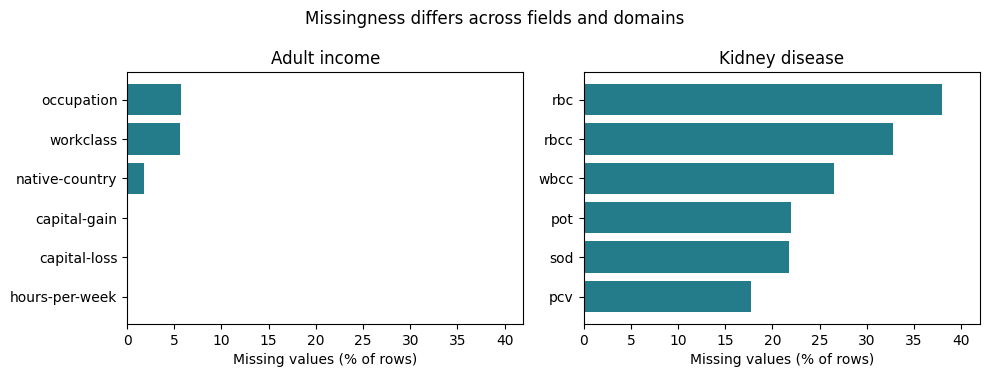

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

for data, axis, name in [
    (adult_features, axes[0], "Adult income"),
    (features, axes[1], "Kidney disease")
]:
    field_missingness = data.isna().mean().mul(100).sort_values().tail(6)
    axis.barh(field_missingness.index, field_missingness.values, color="#247b89")
    axis.set_title(name)
    axis.set_xlabel("Missing values (% of rows)")
    axis.set_xlim(0, 42)

fig.suptitle("Missingness differs across fields and domains")
fig.tight_layout()
fig.savefig("01_missingness.png", dpi=180)
plt.show()

In [30]:
# The Adult split follows the same grouped method used in Phase 1.
adult_canonical = adult_features.fillna("__MISSING__").astype(str)
adult_groups = pd.util.hash_pandas_object(adult_canonical, index=False).astype(str)
adult_group_labels = pd.DataFrame({
    "group": adult_groups, "target": adult_target
}).groupby("group", sort=False)["target"].agg(
    lambda values: int(values.mean() >= 0.5)
)
adult_train_groups, _ = train_test_split(
    adult_group_labels.index,
    test_size=0.20,
    stratify=adult_group_labels.values,
    random_state=42
)
adult_train_index = adult_features.index[adult_groups.isin(adult_train_groups)]

adult_age_limit = calculate_iqr_bounds(
    adult_features.loc[adult_train_index], adult_numeric
)["age"][1]
kidney_sc_limit = calculate_iqr_bounds(
    features.loc[train_index], numeric_columns
)["sc"][1]


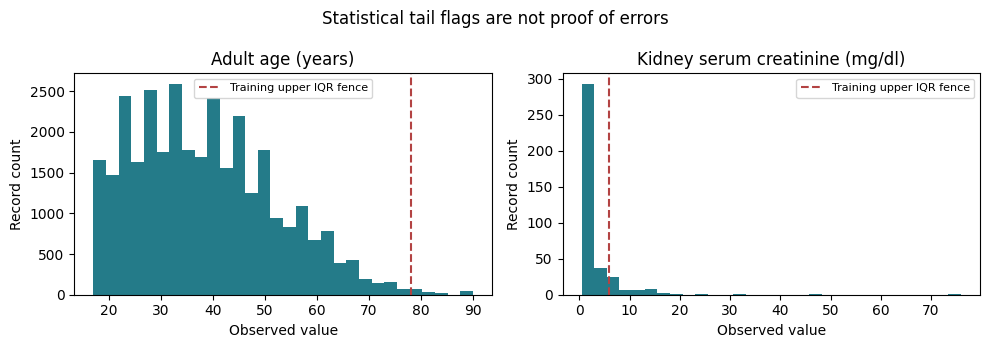

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].hist(adult_features["age"].dropna(), bins=30, color="#247b89")
axes[0].axvline(adult_age_limit, color="#b34343", linestyle="--", label="Training upper IQR fence")
axes[0].set_title("Adult age (years)")
axes[0].set_ylabel("Record count")
axes[0].set_xlabel("Observed value")
axes[0].legend(fontsize=8)

axes[1].hist(features["sc"].dropna(), bins=30, color="#247b89")
axes[1].axvline(kidney_sc_limit, color="#b34343", linestyle="--", label="Training upper IQR fence")
axes[1].set_title("Kidney serum creatinine (mg/dl)")
axes[1].set_ylabel("Record count")
axes[1].set_xlabel("Observed value")
axes[1].legend(fontsize=8)

fig.suptitle("Statistical tail flags are not proof of errors")
fig.tight_layout()
fig.savefig("05_outlier_context.png", dpi=180)
plt.show()

**Comparison:** The same quality checks are useful in both domains, but their severity and modelling effect are different. Missingness is much greater in the kidney data, while class weighting has a much stronger effect on Adult recall.


## Conclusion

The experiments show association, not proof of causation. A cleaning step can improve one metric, reduce another, or make almost no difference. Its value depends on the dataset and the prediction goal.